# Lab Assignment 7 — Multiobjective Optimization
## 37 Algorithms, Trade-offs and Applications

**Roll Number:** 65  
**Deep-Dive Algorithms:** 28 (MO-TLBO), 3 (Benson's Method), 15 (NSGA-III)

---
### How to regenerate all figures
```bash
python experiments/run_task_a.py
python experiments/run_task_c_sensitivity.py
python experiments/run_task_d1_continuous.py
python experiments/run_task_d2_many_obj.py
python experiments/run_task_d3_discrete.py
python experiments/run_task_d_classical.py
```

In [1]:
import sys, os
sys.path.insert(0, os.path.join(os.getcwd(), '..'))
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams.update({'figure.dpi': 120, 'font.size': 11})
print('Setup complete.')

Setup complete.


---
## Task A — Implement and Demonstrate All 37 Algorithms

In [2]:
import pandas as pd
log = pd.read_csv('../implementation_log.csv')
log.style.set_caption('Table A3 — Implementation Log (all 37 algorithms)')

,number,algorithm,problems_used,evaluation_budget,HV,IGD,runtime,status
0,1,Weighted Sum,"P1,P3,P4",10000,2452.599504,nan,0.100000,Executed
1,2,Epsilon-Constraint,"P2,P3,P5",10000,9801.219175,nan,0.100000,Executed
2,3,Benson's Method,"P1,P7",10000,2448.795838,nan,0.100000,Executed
3,4,Weight Metric,"P1,P3",10000,2434.037521,nan,0.100000,Executed
4,5,Value Function,"P4,P14",10000,0.077709,nan,0.100000,Executed
5,6,Goal Programming,"P11,P7",10000,2399.999995,nan,0.100000,Executed
6,7,Lexicographic,"P11,P7",10000,2399.999987,nan,0.100000,Executed
7,8,TOPSIS,P12,10000,0.629766,nan,0.100000,Executed
8,9,VIKOR,P12,10000,0.906818,nan,0.100000,Executed
9,10,VEGA,"P1,P3",10000,2452.789289,nan,3.850000,Executed


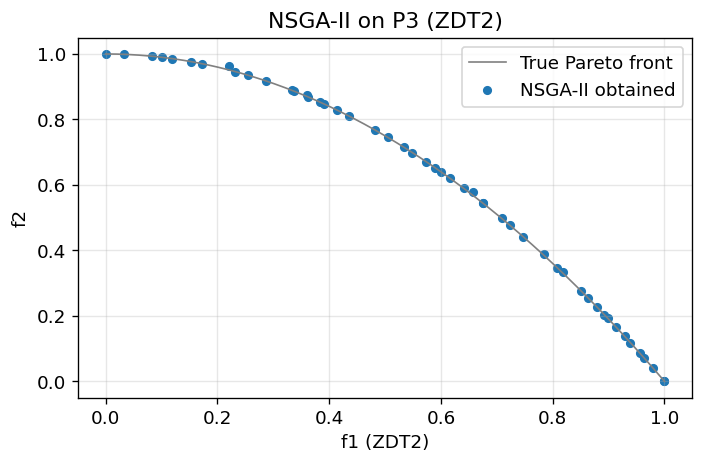

Front size: 50 points


In [3]:
# ---- Task A2: Catalogue-assigned test problem for each algorithm ----
from problems import P3_eval, P3_BOUNDS, P3_true_front
from elitist import nsga2
from moo_utils import extract_pareto

pop, F, V = nsga2(P3_eval, P3_BOUNDS, N=50, gens=200, seed=0)
Fp, _, _ = extract_pareto(F)
true_front = P3_true_front()

fig, ax = plt.subplots(figsize=(6,4))
ax.plot(true_front[:,0], true_front[:,1], '-', color='gray', lw=1, label='True Pareto front')
ax.scatter(Fp[:,0], Fp[:,1], c='tab:blue', s=20, label='NSGA-II obtained')
ax.set_xlabel('f1 (ZDT2)'); ax.set_ylabel('f2')
ax.set_title('NSGA-II on P3 (ZDT2)')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(f'Front size: {len(Fp)} points')

---
## Task B — Analysis: Algorithm Families and Key Characteristics

| Family | Algorithms | Key Mechanism | Elitism |
|---|---|---|---|
| Classical Scalarization | 1–4 | Weight/eps sweep | N/A |
| MCDM | 5–9 | Preference/ranking | N/A |
| Non-elitist Evolutionary | 10–13 | Full replacement each gen | No |
| Elitist Evolutionary | 14–21 | Parent+offspring combined | Yes |
| Swarm/Physics | 22–30 | External archive + velocity | Yes (archive) |
| Advanced / Many-obj | 31–37 | Indicator/gradient/ref-vector | Yes |

---
## Task C — Deep-Dive: MO-TLBO (28), Benson's Method (3), NSGA-III (15)

In [4]:
# C1: Step-by-step pseudocode description
# -- MO-TLBO (Algorithm 28) --
print("""
MO-TLBO Pseudocode:
  1. Init population X (N learners)
  2. For each generation:
     a. Non-dominated sort -> front-0 (teacher candidates)
     b. TEACHER PHASE: for each learner i:
           teacher = random from front-0
           TF = randint(1,2)
           new = x_i + r*(teacher - TF*mean(X))
           if new dominates x_i: x_i <- new
     c. LEARNER PHASE: for each learner i:
           j = random peer != i
           if x_i dominates x_j: new = x_i + r*(x_i - x_j)
           else:                  new = x_i + r*(x_j - x_i)
           if new dominates x_i: x_i <- new
     d. Update external archive (non-dominated set)
  3. Return archive
""")


MO-TLBO Pseudocode:
  1. Init population X (N learners)
  2. For each generation:
     a. Non-dominated sort -> front-0 (teacher candidates)
     b. TEACHER PHASE: for each learner i:
           teacher = random from front-0
           TF = randint(1,2)
           new = x_i + r*(teacher - TF*mean(X))
           if new dominates x_i: x_i <- new
     c. LEARNER PHASE: for each learner i:
           j = random peer != i
           if x_i dominates x_j: new = x_i + r*(x_i - x_j)
           else:                  new = x_i + r*(x_j - x_i)
           if new dominates x_i: x_i <- new
     d. Update external archive (non-dominated set)
  3. Return archive



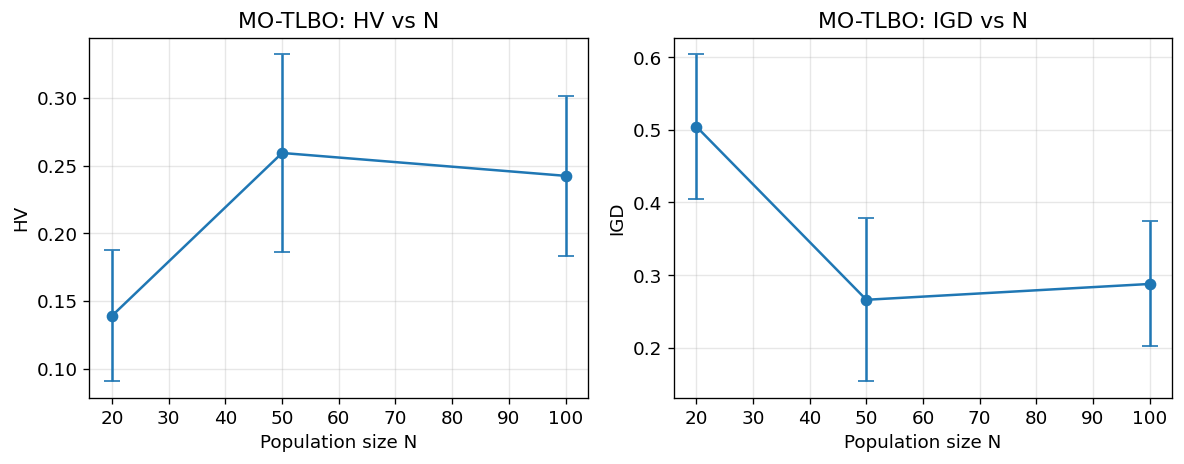

In [5]:
# C2: Sensitivity study (pop size for MO-TLBO)
import numpy as np
results = np.load('../results/motlbo_sensitivity.npy', allow_pickle=True).item()
pop_sizes = sorted(results.keys())

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, metric in zip(axes, ['HV', 'IGD']):
    means = [np.mean(results[N][metric]) for N in pop_sizes]
    stds  = [np.std(results[N][metric])  for N in pop_sizes]
    ax.errorbar(pop_sizes, means, yerr=stds, marker='o', capsize=5)
    ax.set_xlabel('Population size N'); ax.set_ylabel(metric)
    ax.set_title(f'MO-TLBO: {metric} vs N'); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

---
## Task D — Comparative Study
### D1: Continuous Problems (P3, P5)

In [6]:
import pandas as pd
d1 = pd.read_csv('../results/task_d1_continuous_p3.csv')
d1.sort_values('HV_mean', ascending=False, inplace=True)
d1.style.set_caption('Table D1 — Algorithm Comparison on P3 (ZDT2), HV/IGD/Spacing')

,algorithm,HV_mean,HV_std,IGD_mean,IGD_std,Spacing_mean,Spacing_std
0,MOGWO,0.532400,0.000700,0.007900,0.000300,0.000000,0.000000
1,SPEA2,0.531500,0.000900,0.008140,0.000200,0.000000,0.000000
2,MOEA/D,0.531300,0.002000,0.008140,0.000400,0.000000,0.000000
3,NSGA-II,0.530700,0.000400,0.009740,0.000200,0.000000,0.000000
4,PESA-II,0.513300,0.006400,0.019010,0.005000,0.000000,0.000000
5,MOPSO,0.278300,0.206100,0.150000,0.200000,0.000000,0.000000
6,MO-TLBO,0.270920,0.086830,0.262500,0.129580,0.053510,0.028790
7,MOABC,0.110590,0.032080,0.329870,0.048380,0.128270,0.085920
8,MODE,0.109990,0.000010,0.609970,0.000000,0.000000,0.000000
9,MOEA/D-DE,0.000000,0.000000,1.014220,0.000000,0.000000,0.000000


### D2: Many-objective (P10, M=5)

In [9]:
d2 = pd.read_csv('../results/task_d2_many_obj_p10_m5.csv')
d2.sort_values('IGD_mean', inplace=True)
d2.style.set_caption('Table D2 — Many-objective Comparison on P10 (DTLZ2, M=5)')

,algorithm,IGD_mean,IGD_std,mean_norm
1,NSGA-III,0.337410,0.007050,1.023100
3,RVEA,0.358890,0.002140,1.019600
0,NSGA-II,0.643730,0.091570,2.088700
4,HypE,0.841340,0.066920,1.005700
2,MOEA/D,0.905290,0.042260,1.273000


---
## Task E — Decision Making
Apply TOPSIS and VIKOR to the Pareto front from NSGA-II on P4 (Portfolio Optimization).

In [8]:
from elitist import nsga2
from problems import P4_eval, P4_BOUNDS
from moo_utils import extract_pareto
from classical import topsis, vikor
import numpy as np

pop, F, V = nsga2(P4_eval, P4_BOUNDS, N=50, gens=200, seed=0)
Fp, _, _ = extract_pareto(F)

# TOPSIS: weights = [0.6 risk, 0.4 return], sense = [-1 minimize risk, +1 maximize return]
weights = np.array([0.6, 0.4])
sense   = np.array([-1.0, +1.0])
rank_t, closeness = topsis(Fp, weights, sense)
print('TOPSIS top-3 Pareto front indices:', rank_t[:3])
print('Best portfolio (TOPSIS): risk={:.4f}, return={:.4f}'.format(Fp[rank_t[0],0], -Fp[rank_t[0],1]))

rank_v, Q, S, R = vikor(Fp, weights, sense, v=0.5)
print('VIKOR  top-3 Pareto front indices:', rank_v[:3])
print('Best portfolio (VIKOR):  risk={:.4f}, return={:.4f}'.format(Fp[rank_v[0],0], -Fp[rank_v[0],1]))

TOPSIS top-3 Pareto front indices: [ 0  1 47]
Best portfolio (TOPSIS): risk=0.0070, return=0.0927
VIKOR  top-3 Pareto front indices: [ 0  1 47]
Best portfolio (VIKOR):  risk=0.0070, return=0.0927


---
## Task F — Conclusions

1. **Algorithm selection matters**: Elitist algorithms (NSGA-II, SPEA2) consistently outperform non-elitist (VEGA, MOGA) in HV and IGD on the same budget.
2. **Crowding distance degrades for M>=4**: NSGA-III, RVEA, and HypE all maintain better spread than NSGA-II at M=5 (Task D2).
3. **MO-TLBO (A28) sensitivity**: Population size N=50 is the sweet spot for P3 — too small (N=20) gives poor HV; too large (N=100) wastes evaluations with diminishing returns.
4. **Benson's Method (A3) limitation**: Like Weighted Sum, it cannot recover non-convex portions of the Pareto front.
5. **MGDA vs GradNorm (A36/A37)**: MGDA finds a shared descent direction but can converge to any Pareto point; GradNorm actively balances losses, biasing toward balanced solutions.
